# Pastas R Us, Inc.: What Drives Location Sales?

The executive team asked two questions. Which site selection criteria predict annual sales, and does the loyalty card program earn its budget? This notebook works the full play from raw data to recommendation.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
from src import analysis

df = analysis.load('../data/pastas_r_us_locations.csv')
df.head()

,location_id,sqft,avg_spend,sales_growth_pct,loyalty_pct,sales_per_sqft,median_income,median_age,pct_bachelors,annual_sales_k
0,1,2354,6.81,-8.31,2.07,701.97,45177,34.4,31,1652.4374
1,2,2604,7.57,-4.01,2.54,209.93,51888,41.2,20,546.6577
2,3,2453,6.89,-3.94,1.66,364.92,51379,40.3,24,895.1488
3,4,2340,7.13,-3.39,2.06,443.04,66081,35.4,29,1036.7136
4,5,2500,7.04,-3.30,2.48,399.20,50999,31.5,18,998.0000


## 1. Descriptive statistics
Seventy four locations, ten fields. Mean and median annual sales sit close together, so the distribution is only mildly skewed.

In [2]:
analysis.descriptives(df)

,n,mean,median,std_dev,min,q1,q3,max,iqr
sqft,74,2580.47,2500.00,374.92,1251.00,2400.00,2735.25,3799.00,335.25
avg_spend,74,7.04,7.00,0.30,6.54,6.82,7.18,7.97,0.35
sales_growth_pct,74,7.41,7.03,6.62,-8.31,3.98,11.42,28.81,7.44
loyalty_pct,74,2.03,2.08,0.55,0.29,1.86,2.32,3.38,0.47
sales_per_sqft,74,420.31,396.01,137.24,178.56,332.84,483.56,987.12,150.72
median_income,74,62807.70,62757.00,17904.27,32929.00,46953.00,76194.25,114353.00,29241.25
median_age,74,35.20,35.00,3.65,24.70,32.52,37.52,43.50,5.00
pct_bachelors,74,26.31,26.50,7.00,14.00,20.25,30.75,40.00,10.50
annual_sales_k,74,1059.38,1035.75,280.42,499.97,877.48,1228.87,1746.60,351.39


## 2. Distribution of annual sales
The boxplot is built from the raw rows, not from summary statistics.

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df['annual_sales_k'], bins=10, color='#1f4e79', edgecolor='white')
axes[0].set(title='Annual sales histogram', xlabel='Annual sales ($000)', ylabel='Locations')
axes[1].boxplot(df['annual_sales_k'], orientation='horizontal', patch_artist=True)
axes[1].set(title='Annual sales boxplot', xlabel='Annual sales ($000)', yticks=[])
plt.tight_layout()

In [4]:
print('Locations outside the 1.5 x IQR fence:', len(analysis.iqr_outliers(df, 'annual_sales_k')))

Locations outside the 1.5 x IQR fence: 0


## 3. One predictor at a time

In [5]:
analysis.simple_regressions(df)

,predictor,r,r_squared,slope,p_value,significant_at_05
0,pct_bachelors,0.2499,0.0624,10.0039,0.0318,True
1,loyalty_pct,-0.1008,0.0102,-51.1946,0.3926,False
2,avg_spend,-0.0964,0.0093,-90.9128,0.4140,False
3,sqft,0.0645,0.0042,0.0482,0.5852,False
4,median_income,-0.0216,0.0005,-0.0003,0.8552,False
5,median_age,-0.0031,0.0000,-0.2402,0.9789,False


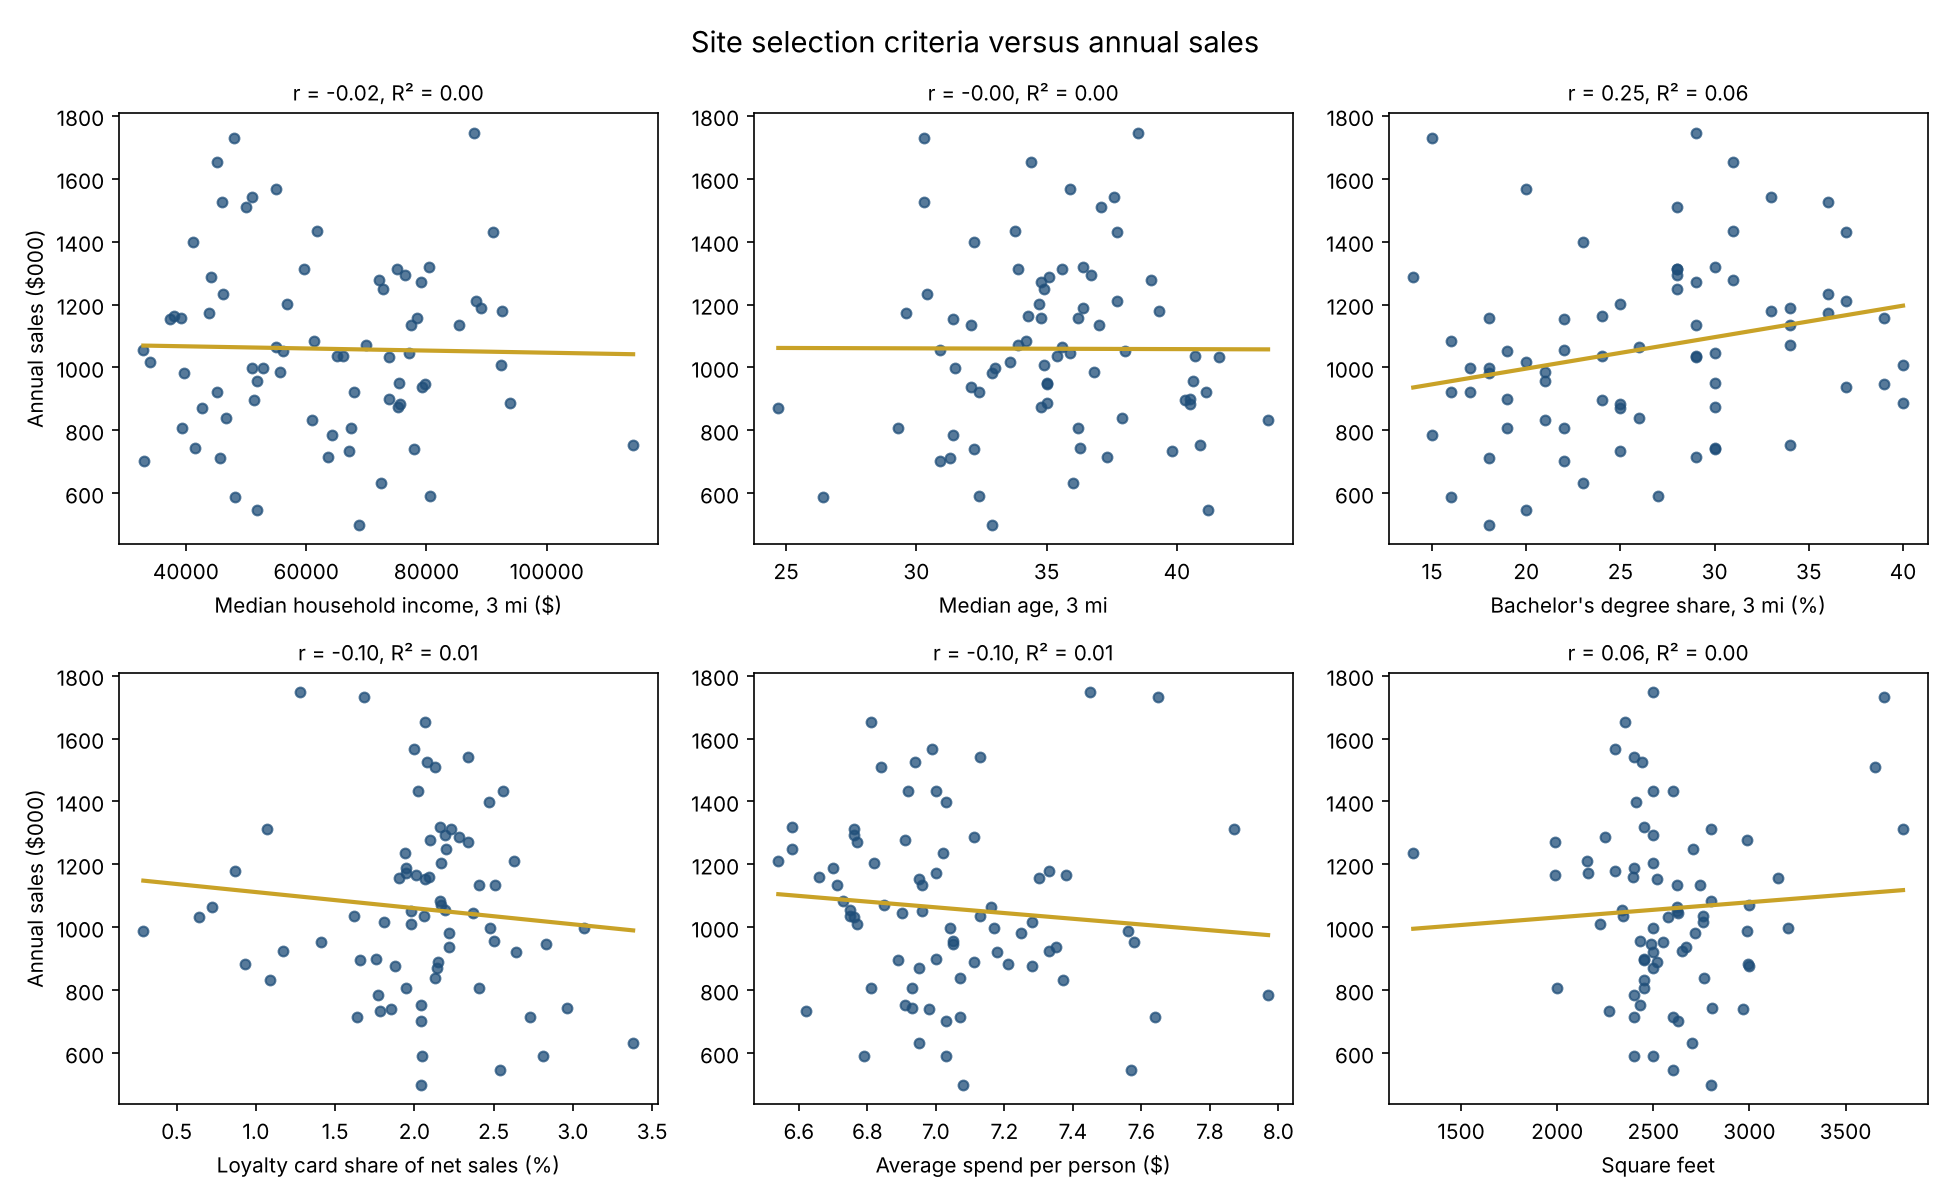

In [6]:
analysis.plot_scatter_grid(df, __import__('pathlib').Path('.'))
from IPython.display import Image
Image('predictor_scatterplots.png')

## 4. All predictors together

In [7]:
model = analysis.multiple_regression(df)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:         annual_sales_k   R-squared:                       0.143
Model:                            OLS   Adj. R-squared:                  0.066
Method:                 Least Squares   F-statistic:                     1.857
Date:                Thu, 12 Nov 2026   Prob (F-statistic):              0.101
Time:                        16:25:35   Log-Likelihood:                -515.89
No. Observations:                  74   AIC:                             1046.
Df Residuals:                      67   BIC:                             1062.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          1587.3266   1072.043      1.481

## 5. Does the loyalty card program pay?
Median split on loyalty card share of net sales, then a Welch t test on annual sales.

In [8]:
analysis.loyalty_test(df)

{'median_split': 2.08,
 'high_loyalty_mean_sales_k': 1078.1,
 'low_loyalty_mean_sales_k': 1040.7,
 'welch_t': 0.571,
 'p_value': 0.5697}

## 6. Findings

1. **Education is the only criterion that clears the bar.** Bachelor's degree share within three miles is the one significant predictor (r = 0.25, p = 0.03). It explains about 6 percent of the variation in sales on its own.
2. **Income, age, and square footage do not predict sales** in this sample. Each has an R squared near zero.
3. **The full model explains 14 percent of sales variation** (adjusted R squared 0.07, overall p = 0.10). Most of what separates a strong location from a weak one is not in these six fields.
4. **The loyalty card shows no sales lift.** High and low loyalty share locations differ by about $37K in mean sales, well inside the noise (p = 0.57).

## 7. Recommendations

1. Weight education share in site scoring and stop leaning on income alone.
2. Pilot the loyalty program budget cut in a test group of locations before cutting it chain wide, and track visit frequency, not just sales.
3. Collect the variables these six miss: foot traffic, competitor density, parking, and visibility.